### Import Libraries

In [1]:
import os, random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

### Functions

In [3]:
def build_baseline():
    inputs = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same")(inputs)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Conv2D(64, kernel_size=(3, 3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs=inputs, outputs=outputs, name="cnn_flatliner_baseline")
    return model

In [4]:
def build_avgpool_variant():
    inputs = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same")(inputs)
    x = layers.AveragePooling2D(pool_size=2)(x)
    x = layers.Conv2D(64, kernel_size=(3, 3), activation="relu", padding="same")(x)
    x = layers.AveragePooling2D(pool_size=2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs=inputs, outputs=outputs, name="cnn_avgpool_flatten")
    return model

In [5]:
def build_gap_variant():
    inputs = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same")(inputs)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(32, kernel_size=(3, 3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    model = keras.Model(inputs=inputs, outputs=outputs, name="cnn_gap_variant")
    return model

In [6]:
def plot_curves(histories, labels, metric="val_accuracy"):
    plt.figure(figsize=(12, 6))
    for history, label in zip(histories, labels):
        plt.plot(history.history[metric], label=f"{label} {metric}")
    plt.title(f"Training and Validation {metric}")
    plt.xlabel("Epochs")
    plt.ylabel(metric)
    plt.legend()
    plt.grid()
    plt.show()

### Obtain Dataset

In [7]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()  

In [8]:
print("Training data shape:", x_train.shape, y_train.shape)
print("Testing data shape:", x_test.shape, y_test.shape)

Training data shape: (60000, 28, 28) (60000,)
Testing data shape: (10000, 28, 28) (10000,)


### Data Preprocessing

In [9]:
x_train = (x_train.astype(np.float32) / 255.0)[..., np.newaxis]
x_test = (x_test.astype(np.float32) / 255.0)[..., np.newaxis]

In [10]:
print("New shape of training data:", x_train.shape)
print("New shape of test data:", x_test.shape)

New shape of training data: (60000, 28, 28, 1)
New shape of test data: (10000, 28, 28, 1)


### Build Model

In [11]:
baseline = build_baseline()
baseline.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
baseline.summary()

Model: "cnn_flatliner_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history_baseline = baseline.fit(x_train, y_train, batch_size=128, epochs=3, validation_split=0.1, verbose=2)

Epoch 1/3
422/422 - 8s - 19ms/step - accuracy: 0.9404 - loss: 0.2049 - val_accuracy: 0.9838 - val_loss: 0.0613
Epoch 2/3
422/422 - 8s - 18ms/step - accuracy: 0.9833 - loss: 0.0544 - val_accuracy: 0.9875 - val_loss: 0.0478
Epoch 3/3
422/422 - 8s - 18ms/step - accuracy: 0.9888 - loss: 0.0361 - val_accuracy: 0.9898 - val_loss: 0.0378


In [13]:
test_loss, test_accuracy = baseline.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Test loss: 0.0319
Test accuracy: 0.9895


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


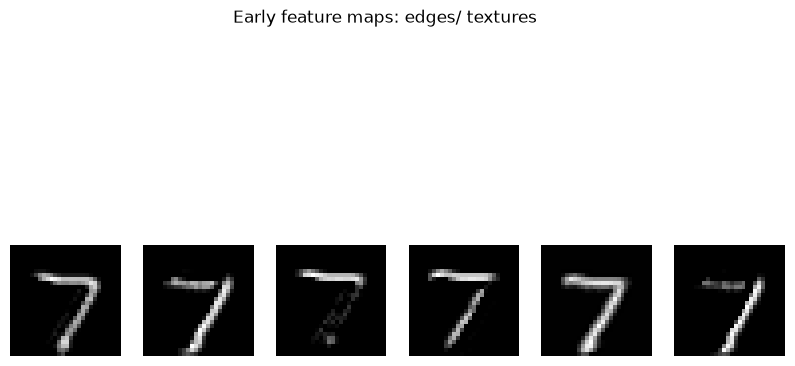

In [14]:
idx = 0
sample = x_test[idx:idx+1]

layer_out_model = keras.Model(inputs=baseline.input, outputs=baseline.layers[1].output)
feature_maps = layer_out_model.predict(sample)

n_show = min(6, feature_maps.shape[-1])
plt.figure(figsize=(10, 6))
for i in range(n_show):
    plt.subplot(1, n_show, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap='gray')
    plt.axis('off')
    
plt.suptitle("Early feature maps: edges/ textures")
plt.show()

### Change Pooling Strategy (Max vs Average)

In [15]:
avgpool_model = build_avgpool_variant()
avgpool_model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
avgpool_model.summary()

Model: "cnn_avgpool_flatten"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 32)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 7, 7, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
history_avg = avgpool_model.fit(x_train, y_train, batch_size=128, epochs=3, validation_split=0.1, verbose=2)

Epoch 1/3
422/422 - 8s - 20ms/step - accuracy: 0.9114 - loss: 0.3044 - val_accuracy: 0.9742 - val_loss: 0.0872
Epoch 2/3
422/422 - 8s - 19ms/step - accuracy: 0.9744 - loss: 0.0828 - val_accuracy: 0.9843 - val_loss: 0.0591
Epoch 3/3
422/422 - 9s - 20ms/step - accuracy: 0.9823 - loss: 0.0565 - val_accuracy: 0.9868 - val_loss: 0.0475


In [17]:
test_loss_avg, test_accuracy_avg = avgpool_model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss (avg pooling): {test_loss_avg:.4f}")
print(f"Test accuracy (avg pooling): {test_accuracy_avg:.4f}")

Test loss (avg pooling): 0.0422
Test accuracy (avg pooling): 0.9862


### Replace Flatten with Global Average Pooling

In [18]:
gap_model = build_gap_variant()
gap_model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
gap_model.summary()

Model: "cnn_gap_variant"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,330 (48.16 KB)

 Trainable params: 12,330 (48.16 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history_gap = gap_model.fit(x_train, y_train, batch_size=128, epochs=3, validation_split=0.1, verbose=2)

Epoch 1/3
422/422 - 8s - 18ms/step - accuracy: 0.3893 - loss: 1.6515 - val_accuracy: 0.5795 - val_loss: 1.2865
Epoch 2/3
422/422 - 5s - 12ms/step - accuracy: 0.6245 - loss: 1.1512 - val_accuracy: 0.7532 - val_loss: 0.8888
Epoch 3/3
422/422 - 5s - 13ms/step - accuracy: 0.7391 - loss: 0.8376 - val_accuracy: 0.8120 - val_loss: 0.6591


In [20]:
test_loss_gap, test_acc_gap = gap_model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss (GAP): {test_loss_gap:.4f}")
print(f"Test accuracy (GAP): {test_acc_gap:.4f}")

Test loss (GAP): 0.6821
Test accuracy (GAP): 0.7958


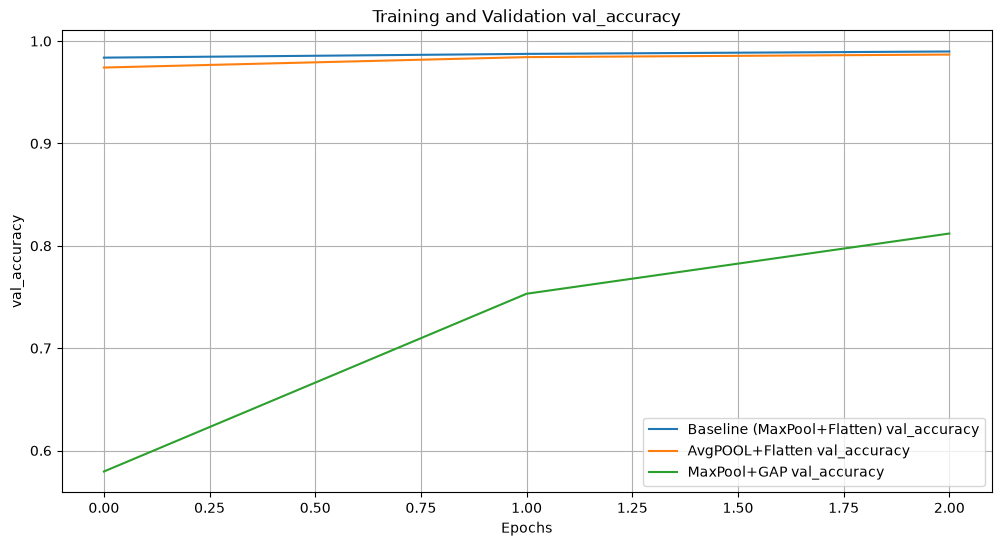

In [21]:
plot_curves([history_baseline, history_avg, history_gap], ["Baseline (MaxPool+Flatten)", "AvgPOOL+Flatten", "MaxPool+GAP"], metric="val_accuracy")